# **EDA Final Project                                                         by: Fay Altheeb**
---



# **Beyond the Scroll: Short Videos and Memory**


## Dataset Overview
This dataset comes from an experiment involving 60 participants.
It compares performance before and after an interruption involving
TikTok, Twitter, YouTube, or rest.

The data includes repeated task attempts, response times,
accuracy summaries, and questionnaire scores.

## Objective
Explore how changes in memory-task performance and response
times differ across the four experimental groups.

## Research Questions
1. How does performance change from before to after the interruption?
2. Does this change differ between TikTok, Twitter, YouTube, and rest?
3. Do the two task types show different patterns?
4. Are faster responses associated with lower accuracy?

## Why This Dataset?
The topic connects everyday social-media habits with measurable
task performance. It allows us to investigate the popular idea of
“brain rot” using evidence, without assuming permanent brain damage.

# **Step 1: Import libraries**

In [2]:
import pandas as pd
import numpy as np


# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# **Step 3: Load the dataset**

In [3]:
df = pd.read_csv("rt.csv")
df.head()

,folder_id,task,interrupt,measure,stimulus,success,correct,rt
0,101,LD,rest,train,TRINKEN,True,True,0.737520
1,101,LD,rest,train,EIRLHCH,True,True,0.849221
2,101,LD,rest,train,PLATZ,True,True,1.225057
3,101,LD,rest,train,ALEEINL,True,True,0.884355
4,101,LD,rest,train,TEHS,True,True,0.755779


# **Step 4: Understand the Datatset**

In [4]:
# Check the number of rows and columns
df.shape

(21480, 8)

In [5]:
# Check the data type of each column
df.dtypes

,0
folder_id,int64
task,object
interrupt,object
measure,object
stimulus,object
success,bool
correct,bool
rt,float64


In [6]:
# Check data types and the number of non-missing values in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21480 entries, 0 to 21479
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   folder_id  21480 non-null  int64  
 1   task       21480 non-null  object 
 2   interrupt  21480 non-null  object 
 3   measure    21480 non-null  object 
 4   stimulus   21480 non-null  object 
 5   success    21480 non-null  bool   
 6   correct    21480 non-null  bool   
 7   rt         21377 non-null  float64
dtypes: bool(2), float64(1), int64(1), object(4)
memory usage: 1.0+ MB


In [7]:
# Summarize numerical columns using counts, averages, and ranges
df.describe()

,folder_id,rt
count,21480.000000,21377.000000
mean,258.000000,0.861702
std,111.889452,0.363158
min,101.000000,0.007295
25%,179.500000,0.627431
50%,258.000000,0.738940
75%,336.500000,0.967457
max,415.000000,2.959757


In [8]:
# Count missing values in each column
df.isnull().sum()

,0
folder_id,0
task,0
interrupt,0
measure,0
stimulus,0
success,0
correct,0
rt,103


In [9]:
# Calculate the percentage of missing values in each column
df.isna().mean() * 100

,0
folder_id,0.000000
task,0.000000
interrupt,0.000000
measure,0.000000
stimulus,0.000000
success,0.000000
correct,0.000000
rt,0.479516


In [10]:
# Check for identical rows; investigate before deciding whether to remove them
df.duplicated().sum()

np.int64(1)

In [11]:
# Count test attempts for each task type
df["task"].value_counts(dropna=False)

,count
task,
LD,19698
PM,1782


# **Step 4: Data Cleaning**

### 1. Missing Values
The response-time column (`rt`) has 103 missing values.
will keep these attempts and leave their response times missing,
because filling them with a mean or median would invent measurements.
then exclude missing times only when analysing response time.

### 2. Duplicate Rows
There is one exact duplicate row.
will inspect both copies before deciding whether to remove it.
Repeated trials can look identical, so matching values alone do not
prove that a row was accidentally duplicated.

### 3. Unclear Column Names
Some column names are difficult to understand.
We will rename:
- `folder_id` to `participant_id`
- `interrupt` to `interruption_group`
- `measure` to `phase`
- `rt` to `response_time`

### 4. Data types
alla columns had there actual data types correctly but the Participant IDs are identifiers, not numerical measurements. Will convert them to strings to prevent treating them as numerical values.

In [12]:
# Show rows with missing response times
df[df["rt"].isna()]

,folder_id,task,interrupt,measure,stimulus,success,correct,rt
6,101,PM,rest,train,MENGE,False,False,NaN
65,101,PM,rest,pre,GEFÜHL,False,False,NaN
542,201,PM,tiktok,post,HÄNE,False,False,NaN
717,301,PM,youtube,train,EIRLHCH,False,False,NaN
723,301,PM,youtube,train,BENTES,False,False,NaN
...,...,...,...,...,...,...,...,...
20668,215,PM,tiktok,post,BIER,False,False,NaN
20713,215,PM,tiktok,post,ANSEHEN,False,False,NaN
20729,215,PM,tiktok,post,RAKTE,False,False,NaN
20765,315,PM,youtube,train,EIRLHCH,False,False,NaN


In [13]:
# Display both copies of the duplicated row
df[df.duplicated(keep=False)]

,folder_id,task,interrupt,measure,stimulus,success,correct,rt
13093,110,PM,rest,post,BLAU,False,False,NaN
13142,110,PM,rest,post,BLAU,False,False,NaN


In [14]:
# Remove exact duplicates and reset the index
df = df.drop_duplicates().reset_index(drop=True)

In [15]:
# Rename unclear columns
df = df.rename(columns={
    "folder_id": "participant_id",
    "interrupt": "interruption_group",
    "measure": "phase",
    "rt": "response_time"
})

# Preview the updated dataset
df.head()

,participant_id,task,interruption_group,phase,stimulus,success,correct,response_time
0,101,LD,rest,train,TRINKEN,True,True,0.737520
1,101,LD,rest,train,EIRLHCH,True,True,0.849221
2,101,LD,rest,train,PLATZ,True,True,1.225057
3,101,LD,rest,train,ALEEINL,True,True,0.884355
4,101,LD,rest,train,TEHS,True,True,0.755779


In [16]:
# Store participant IDs as labels rather than numerical measurements
df["participant_id"] = df["participant_id"].astype("string")

# **Step 5: Feature Engineering**


1. **Stimulus Length:** Calculate the number of characters in each stimulus to investigate whether longer stimuli are associated with slower responses or lower accuracy.

2. **Performance Change:** Measure how each participant's accuracy changes before and after an interruption.

   Performance Change = Post Accuracy − Pre Accuracy



In [17]:
# Create a feature representing the length of each stimulus
df["stimulus_length"] = df["stimulus"].str.len()

# Preview the new feature
df[["stimulus", "stimulus_length"]].head()


,stimulus,stimulus_length
0,TRINKEN,7
1,EIRLHCH,7
2,PLATZ,5
3,ALEEINL,7
4,TEHS,4


In [18]:

# Calculate the average correctness for each participant before and after the interruption
performance = (
    df[df["phase"].isin(["pre", "post"])]
    .groupby(["participant_id", "interruption_group", "task", "phase"])["correct"]
    .mean()
    .reset_index(name="accuracy")
)

# Preview the accuracy results
performance.head()


,participant_id,interruption_group,task,phase,accuracy
0,101,rest,LD,post,0.993750
1,101,rest,LD,pre,0.968553
2,101,rest,PM,post,1.000000
3,101,rest,PM,pre,0.866667
4,102,rest,LD,post,0.968750


In [19]:

# Reshape the data to compare pre and post accuracy
change = performance.pivot(
    index=["participant_id", "interruption_group", "task"],
    columns="phase",
    values="accuracy"
).reset_index()

# Calculate accuracy change after the interruption
change["accuracy_change"] = change["post"] - change["pre"]

# Preview the new feature
change.head()


phase,participant_id,interruption_group,task,post,pre,accuracy_change
0,101,rest,LD,0.99375,0.968553,0.025197
1,101,rest,PM,1.00000,0.866667,0.133333
2,102,rest,LD,0.96875,0.927273,0.041477
3,102,rest,PM,1.00000,0.777778,0.222222
4,103,rest,LD,0.98750,0.987500,0.000000


# **Step 5: Exploratory Data Analysis (EDA)**

## 1. Univariate Analysis

- Distribution of response times
- Distribution of stimulus lengths
- Frequency of task types
- Distribution of accuracy changes


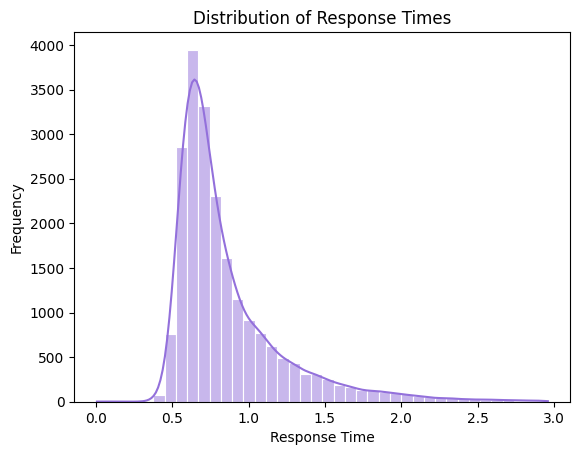

In [20]:
# Plot the distribution of response times
sns.histplot(data=df, x="response_time", bins=40, kde=True, color="mediumpurple", edgecolor="white")

plt.title("Distribution of Response Times")
plt.xlabel("Response Time")
plt.ylabel("Frequency")
plt.show()


# Right-skewed distribution: Most participants' responses are relatively fast, with a long tail toward slower response times.
# Highest frequency: Most responses are concentrated around 0.5–0.9.
# Peak: The most common response times appear to be around 0.6–0.7.



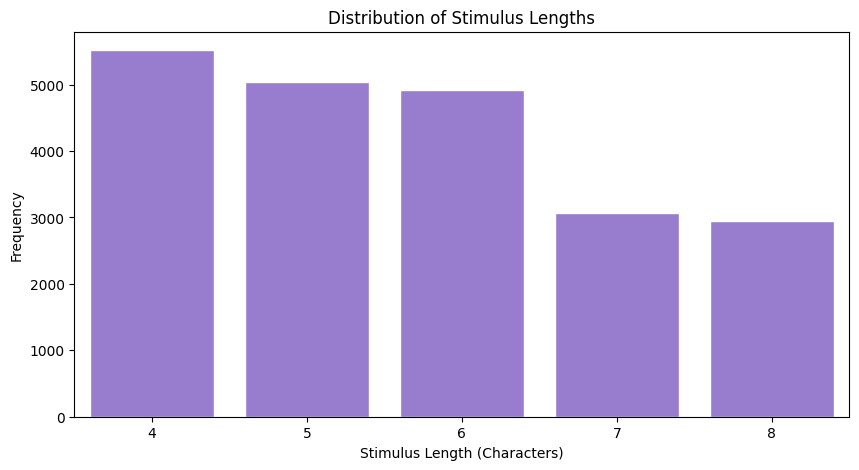

In [21]:

plt.figure(figsize=(10, 5))

# Plot the distribution of stimulus lengths
sns.countplot(data=df,x="stimulus_length",color="mediumpurple",edgecolor="white")

plt.title("Distribution of Stimulus Lengths")
plt.xlabel("Stimulus Length (Characters)")
plt.ylabel("Frequency")
plt.show()


# Insight: Distribution of Stimulus Lengths
# Stimulus lengths range from 4 to 8 characters, with 4-character stimuli appearing most frequently. Shorter stimuli (4–6 characters) occur more often than longer ones (7–8 characters).
# This shows how stimulus lengths are distributed across the experiment, but further analysis is needed to determine whether length is associated with response time or accuracy.


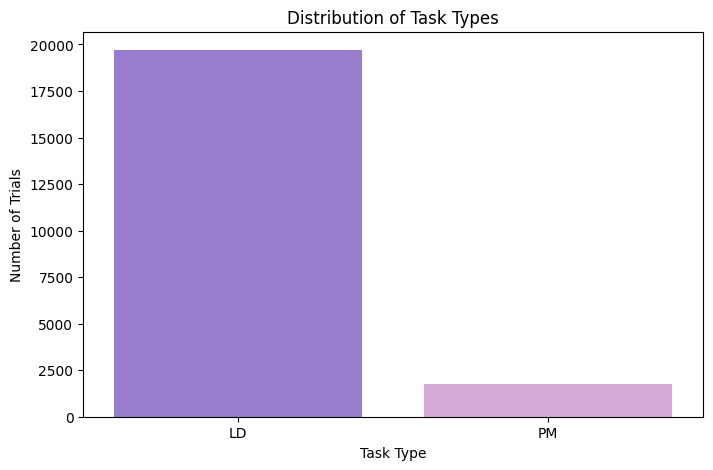

In [22]:

plt.figure(figsize=(8, 5))

# Compare the number of trials for each task
sns.countplot(data=df,x="task",hue="task",palette=["mediumpurple", "plum"],legend=False)

plt.title("Distribution of Task Types")
plt.xlabel("Task Type")
plt.ylabel("Number of Trials")
plt.show()

# Insight: Distribution of Task Types
# Lexical Decision (LD) trials occur much more frequently than Prospective Memory (PM) trials.
# This difference is expected because LD is the main ongoing task, while PM occurs only when participants encounter a specific memory cue.
# Therefore, the unequal distribution reflects the experimental design rather than a data quality issue.

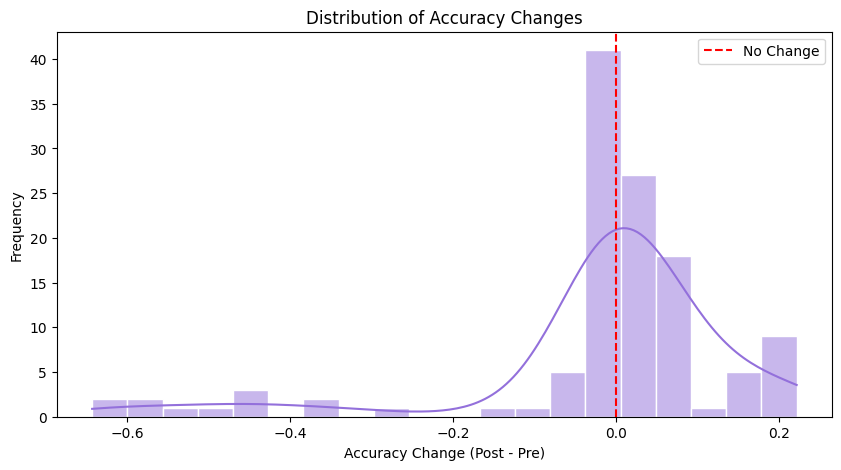

In [23]:

plt.figure(figsize=(10, 5))

# Plot the distribution of participants' accuracy changes
sns.histplot(data=change,x="accuracy_change",bins=20,kde=True,color="mediumpurple",edgecolor="white")

# Add a reference line for no performance change
plt.axvline(0, color="red", linestyle="--", label="No Change")

plt.title("Distribution of Accuracy Changes")
plt.xlabel("Accuracy Change (Post - Pre)")
plt.ylabel("Frequency")
plt.legend()
plt.show()


# Insight: Distribution of Accuracy Changes
# Most accuracy changes are concentrated around zero, indicating that participants generally showed little change in performance after the interruption.
# However, the distribution has a longer negative tail, with some participants experiencing substantial declines in accuracy.
# This suggests that while most participants maintained relatively stable performance, further analysis is needed to determine how accuracy changes differ across interruption groups.

# 2. Bivariate Analysis
- Comparison of accuracy before and after interruptions
- Accuracy changes across interruption groups (TikTok, YouTube, Twitter, and Rest)
- Comparison of response times across interruption groups
- Relationship between stimulus length and response time
- Relationship between response time and accuracy
- Correlations between numerical variables

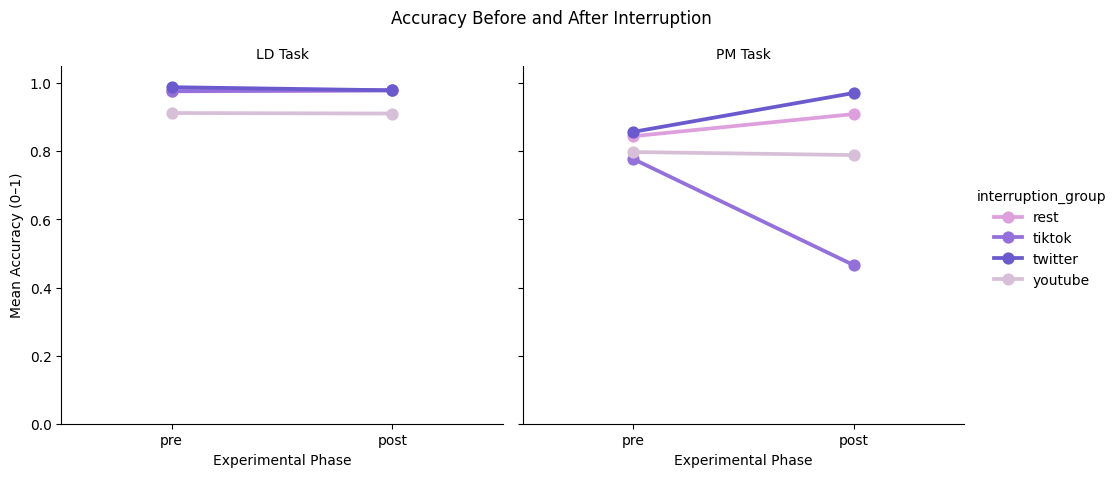

In [24]:
accuracy_summary = (
    performance.groupby(["interruption_group", "task", "phase"], as_index=False)["accuracy"]
    .mean()
)

fig = sns.catplot(
    data=accuracy_summary,
    x="phase", y="accuracy", hue="interruption_group", col="task",
    kind="point", order=["pre", "post"],
    hue_order=["rest", "tiktok", "twitter", "youtube"],
    palette=["plum", "mediumpurple", "slateblue", "thistle"],
    height=4.5, aspect=1.1, errorbar=None
)
fig.set_axis_labels("Experimental Phase", "Mean Accuracy (0–1)")
fig.set_titles("{col_name} Task")
fig.set(ylim=(0, 1.05))
fig.fig.suptitle("Accuracy Before and After Interruption", y=1.05)
plt.show()

# Insight: Accuracy Before and After Interruption
# LD accuracy remains nearly unchanged across the four groups, whereas PM accuracy shows larger differences.
# TikTok PM accuracy falls from approximately 77.8% before to 46.6% after the interruption, while Rest and Twitter improve.
# These are descriptive differences; this plot alone does not establish that the interruption caused the change.

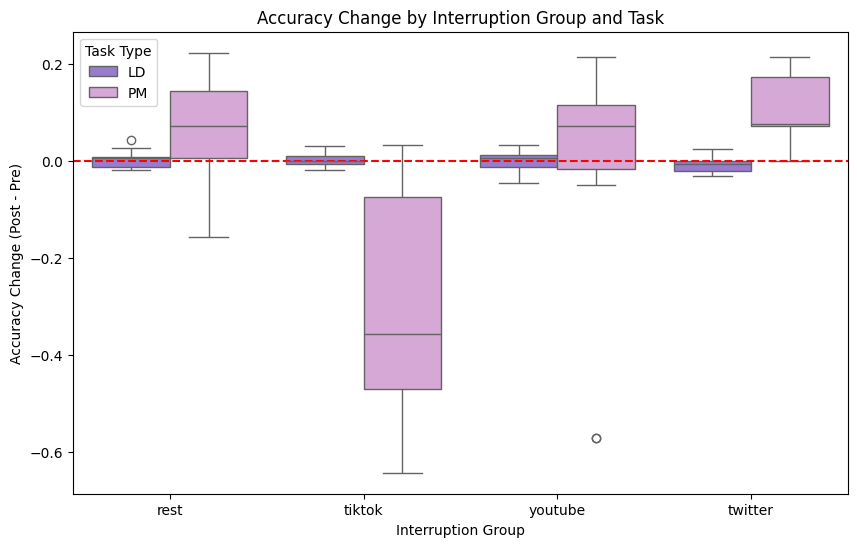

In [ ]:
plt.figure(figsize=(10, 6))

# Compare accuracy changes across interruption groups and tasks
sns.boxplot(
    data=change,
    x="interruption_group",
    y="accuracy_change",
    hue="task",
    palette=["mediumpurple", "plum"]
)

# Reference line indicating no accuracy change
plt.axhline(0, color="red", linestyle="--")

plt.title("Accuracy Change by Interruption Group and Task")
plt.xlabel("Interruption Group")
plt.ylabel("Accuracy Change (Post - Pre)")
plt.legend(title="Task Type")
plt.show()

# Insight: Accuracy Change by Interruption Group and Task
# TikTok shows the largest mean PM accuracy decline (-31.2 percentage points), with 12 of its 15 participants declining.
# Rest (+6.5 pp) and Twitter (+11.4 pp) show average PM improvements, while YouTube is nearly unchanged on average (-0.9 pp).
# PM results also show much greater variability than LD, so it is important to compare both tasks separately.

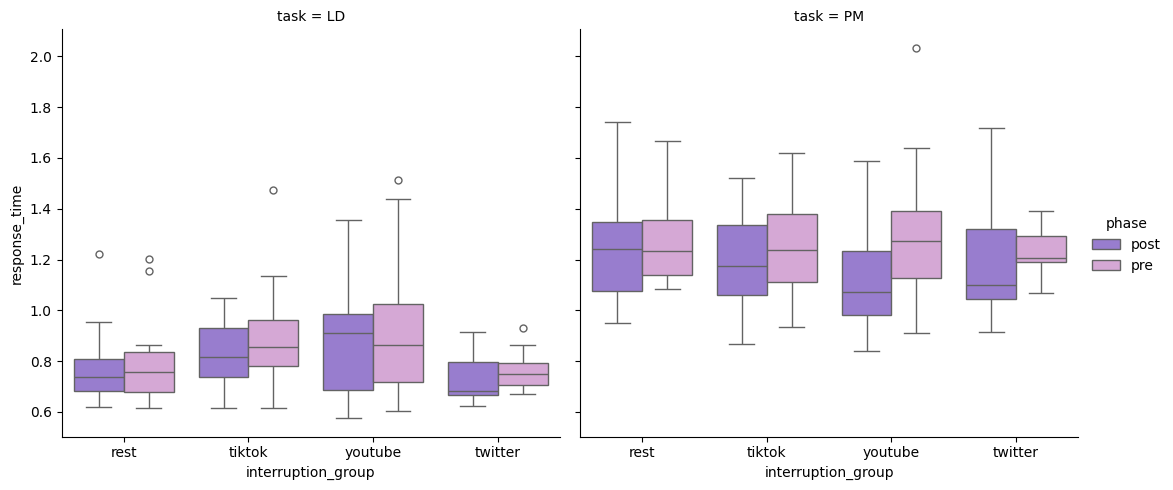

In [ ]:

# Calculate average response time for each participant, task, and phase
rt_summary = (
    df[df["phase"].isin(["pre", "post"])]
    .groupby(["participant_id", "interruption_group", "task", "phase"])["response_time"]
    .mean()
    .reset_index()
)

# Compare response times before and after each interruption
sns.catplot(
    data=rt_summary,
    x="interruption_group",
    y="response_time",
    hue="phase",
    col="task",
    kind="box",
    palette=["mediumpurple", "plum"],
    height=5,
    aspect=1.1
)

plt.show()

# Insight: Response Time by Interruption Group
# PM trials generally take longer than LD trials, reflecting the different demands of the tasks.
# Average participant response times are slightly faster after the interruption in every group for both tasks.
# Faster responses do not necessarily indicate better performance: TikTok PM accuracy declines even though its mean response time decreases.

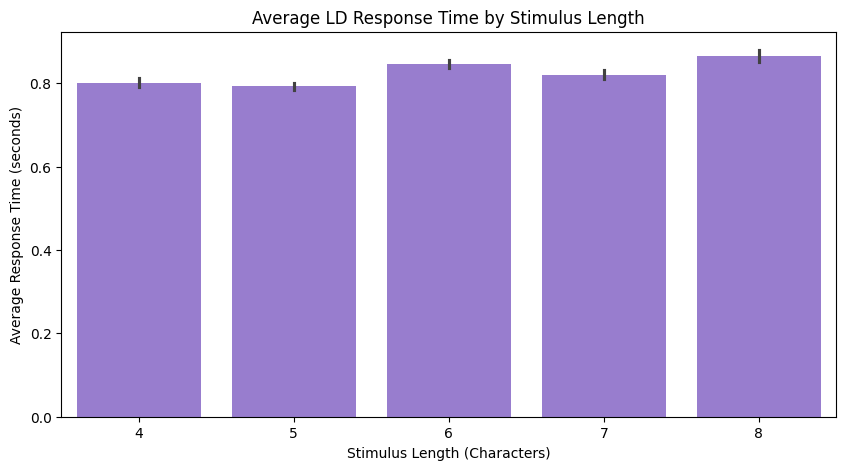

In [26]:

plt.figure(figsize=(10, 5))

# Compare average response times across stimulus lengths and tasks
ld_trials = df[(df["task"] == "LD") & (df["phase"].isin(["pre", "post"]))]
sns.barplot(
    data=ld_trials,
    x="stimulus_length", y="response_time",
    color="mediumpurple", errorbar=("ci", 95)
)
plt.title("Average LD Response Time by Stimulus Length")
plt.xlabel("Stimulus Length (Characters)")
plt.ylabel("Average Response Time (seconds)")
plt.show()

# Insight: Stimulus Length and Response Time
# LD responses are slightly slower on average for eight-character stimuli (about 0.87 seconds) than five-character stimuli (about 0.79 seconds).
# However, the differences between lengths are relatively small and are not perfectly increasing.
# Stimulus length alone does not appear to explain most variation in response time; word properties and participant differences may also matter.

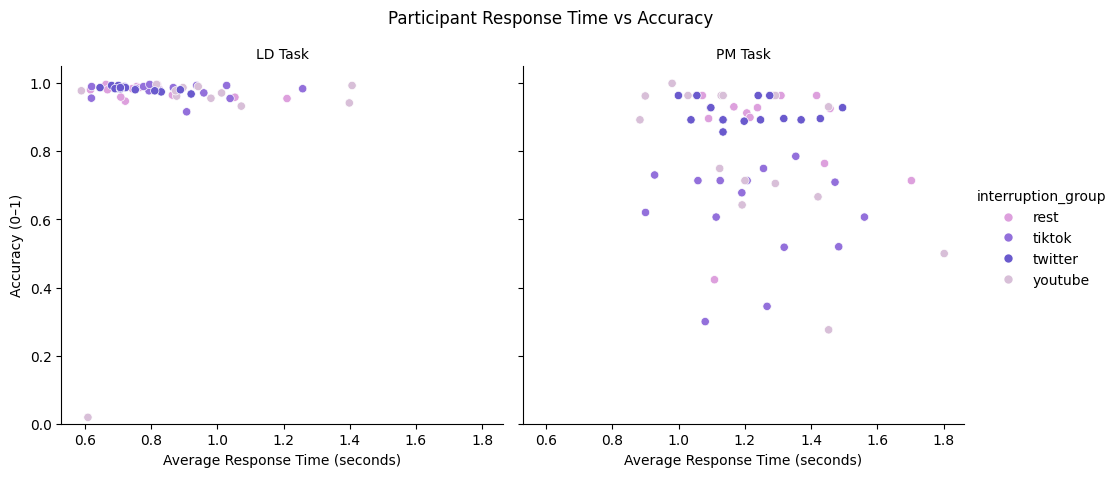

In [27]:

# Calculate average response time and correctness for each participant and task
speed_accuracy = (
    df[df["phase"].isin(["pre", "post"])]
    .groupby(["participant_id", "interruption_group", "task"])
    .agg(avg_response_time=("response_time", "mean"), accuracy=("correct", "mean"))
    .reset_index()
)

fig = sns.relplot(
    data=speed_accuracy,
    x="avg_response_time", y="accuracy", col="task", hue="interruption_group",
    hue_order=["rest", "tiktok", "twitter", "youtube"],
    palette=["plum", "mediumpurple", "slateblue", "thistle"],
    height=4.5, aspect=1.1
)
fig.set_axis_labels("Average Response Time (seconds)", "Accuracy (0–1)")
fig.set_titles("{col_name} Task")
fig.set(ylim=(0, 1.05))
fig.fig.suptitle("Participant Response Time vs Accuracy", y=1.05)
plt.show()

# Insight: Response Time and Accuracy
# There is no strong overall relationship between faster responses and lower correctness.
# Across participants, the correlation is weak for LD (r about +0.10) and modestly negative for PM (r about -0.25).
# An unusually low LD accuracy value appears for one YouTube participant; it should be checked, not automatically removed.


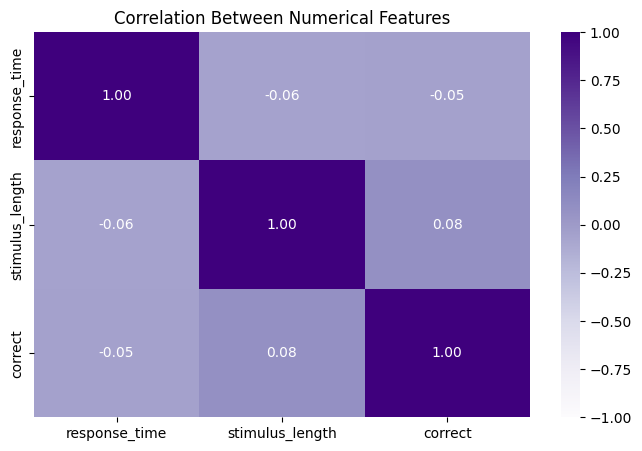

In [ ]:

plt.figure(figsize=(8, 5))

# Calculate correlations between numerical features
corr = df[["response_time", "stimulus_length", "correct"]].corr()

# Visualize the correlation matrix
sns.heatmap(
    corr,
    annot=True,
    cmap="Purples",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Numerical Features")
plt.show()

# Insight: Correlation Heatmaps
# Overall linear correlations between response time, stimulus length, and correctness are weak (absolute r under 0.09).


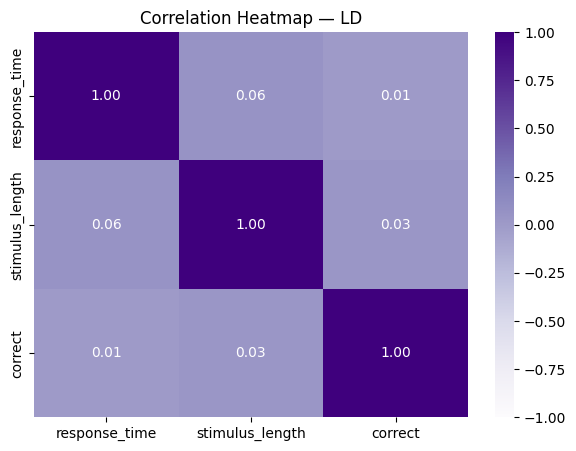

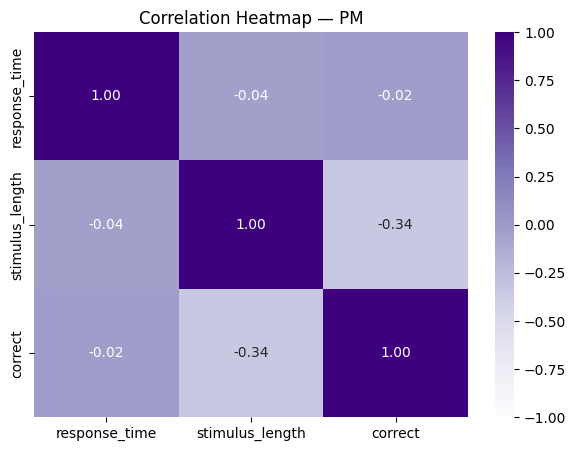

In [ ]:

# Compare correlations separately for LD and PM
for task in ["LD", "PM"]:
    plt.figure(figsize=(7, 5))

    corr = df[df["task"] == task][
        ["response_time", "stimulus_length", "correct"]
    ].corr()

    sns.heatmap(
        corr,
        annot=True,
        cmap="Purples",
        vmin=-1,
        vmax=1,
        center=0,
        fmt=".2f"
    )

    plt.title(f"Correlation Heatmap — {task}")
    plt.show()

# Insight: Correlation Heatmaps
# Within LD, stimulus length and response time have a very weak positive correlation (r about +0.06).
# PM stimulus lengths have almost no variation; the apparent PM length-correctness correlation is not reliable evidence of an effect.

**# Step 7: Insights Summary & Conclusion**

## Answers to the Research Questions

**1. How does performance change from before to after the interruption?**

The results show that performance changes depend on the type of memory task. Lexical Decision (LD) accuracy remains relatively stable before and after interruptions, while Prospective Memory (PM) shows more noticeable changes. This suggests that remembering an intended action may be more affected by interruptions than identifying words.

**2. Does this change differ between TikTok, Twitter, YouTube, and Rest?**

Yes. The TikTok group shows the most noticeable decline in Prospective Memory accuracy after the interruption. In comparison, the Twitter and Rest groups generally show improvements, while the YouTube group remains relatively stable on average. This suggests that different interruption conditions may relate to different memory outcomes.

**3. Do the two task types show different patterns?**

Yes. Lexical Decision is performed more frequently and shows more consistent accuracy across participants. Prospective Memory occurs less frequently and shows greater variation in performance. This difference suggests that remembering to perform a planned action may be more sensitive to interruptions than completing an ongoing task.

**4. Are faster responses associated with lower accuracy?**

Not necessarily. Although response times generally become slightly faster after interruptions, accuracy does not always improve or decline alongside response speed. The relationship between response time and correctness is relatively weak, meaning faster responses do not consistently indicate poorer performance.

## Overall Insights

**Patterns Discovered**

The clearest pattern is that Prospective Memory changes more noticeably than Lexical Decision after interruptions. Most participants show relatively small changes, but some experience substantial declines, particularly in the TikTok group.

**Interesting Relationships**

Prospective Memory responses generally take longer than Lexical Decision responses. Stimulus length appears to have only a weak relationship with response time, and faster responses are not consistently linked to lower accuracy.

**Outliers**

A small number of participants show unusually large decreases in accuracy or slower response times. These observations highlight individual differences in performance and explain why group averages may not represent every participant's experience.

**Key Takeaways**

The findings suggest that the type of interruption matters, especially for tasks that require remembering an intention. However, the results also show considerable differences between individuals, and the observed patterns should not be interpreted as proof that social media directly causes memory impairment.

## Final Conclusion

This project explored how different social media interruptions relate to memory performance and response times. The analysis suggests that **Prospective Memory is more sensitive to changes following interruptions than Lexical Decision**, with the TikTok group showing the strongest average decline.

Overall, the findings highlight a possible relationship between short-form video interruptions and difficulties in remembering intended actions. However, these conclusions are based on exploratory analysis of one experiment and do not establish long-term effects or prove that TikTok causes memory loss.

# **Appendix: Original Column Descriptions**

Each row represents one experimental task attempt. The dictionary below refers to the original rt.csv column names.
Each row represents one participant’s attempt at an experimental task.

| Column | Description |
|--------|-------------|
| `folder_id` | Participant identifier. It is a label, not a numerical measurement. |
| `task` | Task type: `LD` = Lexical Decision, identifying real versus made-up words; `PM` = Prospective Memory, remembering to perform a previously instructed action. |
| `interrupt` | Interruption group: `tiktok`, `twitter`, `youtube`, or `rest`. |
| `measure` | Experimental phase: `train` = practice, `pre` = before the interruption, and `post` = after the interruption. |
| `stimulus` | The word or letter sequence presented during the attempt. |
| `success` | Boolean outcome flag supplied by the researchers. Its exact definition needs verification before interpretation. |
| `correct` | Boolean correctness flag supplied by the researchers. We need to verify how it differs from `success`. |
| `rt` | Recorded response time. Missing values indicate that no response-time value is available. The measurement unit needs confirmation from the documentation. |

Participants appear in multiple rows because each completed many attempts.
The `train` phase refers to practice trials, not machine-learning training data.